# Demanda de Inventario de Grupo Bimbo (Descripcion)



## 1. Tiempo y logística

* **`Semana` (Número de semana):** Representa el período de tiempo de la transacción. La semana operativa de Grupo Bimbo comprende desde el jueves hasta el miércoles.
* **`Agencia_ID` (Identificador de agencia):** Identifica el centro de distribución físico donde se cargan los camiones de reparto con productos frescos.
* **`Canal_ID` (Identificador de canal de ventas):** Identifica la categoría del cliente, como pequeñas tiendas de barrio (*tienditas*), grandes supermercados y tiendas de conveniencia.
* **`Ruta_SAK` (Identificador de ruta):** Identifica la ruta geográfica específica que recorre un camión de reparto. Una misma agencia puede tener varias rutas de distribución.

## 2. Entidades

* **`Cliente_ID` y `NombreCliente` (Identificador y nombre del cliente):** Identifican la tienda específica que recibe la entrega, como «Abarrotes La Lupita» o una sucursal de Walmart.
* **`Producto_ID` y `NombreProducto` (Identificador y nombre del producto):** Identifican el producto específico que se entrega, incluyendo su marca, nombre y peso. Por ejemplo, «Pan Blanco Bimbo 680 g».

## 3. Flujo de transacciones

* **`Venta_uni_hoy` (Unidades entregadas esta semana):** Número de unidades de producto que el conductor entrega físicamente a la tienda durante la semana actual.
* **`Venta_hoy` (Ingresos por ventas de esta semana):** Ingresos brutos, expresados en pesos mexicanos, correspondientes a las unidades entregadas a la tienda.
* **`Dev_uni_proxima` (Unidades devueltas la próxima semana):** Número de unidades de la entrega actual que no se vendieron antes de caducar. El conductor recoge estos productos vencidos, conocidos como *merma por caducidad*, durante la entrega de la semana siguiente.
* **`Dev_proxima` (Valor de las devoluciones de la próxima semana):** Valor monetario, expresado en pesos mexicanos, reembolsado o acreditado a la tienda por las unidades devueltas debido a su caducidad.

## 4. Variable objetivo: `Demanda_uni_equil`

La **demanda ajustada** es la variable objetivo que se busca predecir. Representa una estimación de la demanda del consumidor final: la cantidad de unidades de producto que los consumidores realmente compraron, en lugar de limitarse a contar las unidades entregadas a una tienda.

# Analisis Exploratorio de la base de datos

In [1]:
import matplotlib.pyplot as plt
import pandas as pd 
import numpy as np
import copy
import os
import seaborn as sns
from sklearn.linear_model import LinearRegression

In [2]:
print(os.getcwd())

C:\Users\alexi\OneDrive\Escritorio\Personal\Proyecto_DL\backend\ai


In [3]:
dtypes = { #se trata de bajar la memoria de los datos para mejorar la lectura de datos 
    'Semana': 'int8',
    'Agencia_ID': 'int16',
    'Canal_ID': 'int8',
    'Ruta_SAK': 'int32',
    'Cliente_ID': 'int32',
    'Producto_ID': 'int32',
    'Venta_uni_hoy': 'int32',
    'Venta_hoy': 'float32',
    'Dev_uni_proxima': 'int32',
    'Dev_proxima': 'float32',
    'Demanda_uni_equil': 'int32'
}

productos = pd.read_csv("../data/raw/producto_tabla.csv") 
clientes = pd.read_csv("../data/raw/cliente_tabla.csv")

#df = pd.read_csv("../data/raw/train.csv", dtype=dtypes) #nrows=3_000_000) #May change | skiprows=range(1, 50_000_001), , nrows=6_000_000

In [4]:
sample_fractions = []

for chunk in pd.read_csv("../data/raw/train.csv", dtype=dtypes, chunksize=1_000_000):
   
    sampled_chunk = chunk.sample(frac=0.03, random_state=42)
    sample_fractions.append(sampled_chunk)

full_sample = pd.concat(sample_fractions, ignore_index=True)


final_df = full_sample.groupby('Semana').apply(
    lambda x: x.sample(n=300_000, random_state=42)
).reset_index(drop=True)

C:\Users\alexi\AppData\Local\Temp\ipykernel_12108\2292162375.py:11: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  final_df = full_sample.groupby('Semana').apply(


In [6]:
listita = final_df['Semana'].unique()
for i in range(2,11):
    print( f" Semana {i} tiene: {(final_df['Semana'] == i).sum()} registros")

 Semana 2 tiene: 0 registros
 Semana 3 tiene: 300000 registros
 Semana 4 tiene: 300000 registros
 Semana 5 tiene: 300000 registros
 Semana 6 tiene: 300000 registros
 Semana 7 tiene: 300000 registros
 Semana 8 tiene: 300000 registros
 Semana 9 tiene: 300000 registros
 Semana 10 tiene: 0 registros


In [30]:
listaCount = final_df['Producto_ID'].value_counts()
print(listaCount.head(10))

Producto_ID
1240     60398
1242     58081
2233     56058
1250     52749
1284     47243
1146     42204
1232     41721
1278     39686
1109     38444
41938    38321
Name: count, dtype: int64


In [27]:
top_10_ids = listaCount.head(10).index.tolist()

# 2. Filter the main DataFrame to keep only those 10 products
df_top10 = final_df[final_df['Producto_ID'].isin(top_10_ids)]

# 3. Sample exactly 38,000 rows per product
df_sampled = (
    df_top10
    .groupby('Producto_ID', as_index=False, group_keys=False)
    .apply(lambda g: g.sample(n=38_000, random_state=42))
    .reset_index(drop=True)
)

C:\Users\alexi\AppData\Local\Temp\ipykernel_12108\3957280279.py:10: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(n=38_000, random_state=42))


In [28]:
for i in range(3,10):
    print( f" Semana {i} tiene: {(df_top10['Semana'] == i).sum()} registros")

 Semana 3 tiene: 66683 registros
 Semana 4 tiene: 66120 registros
 Semana 5 tiene: 67796 registros
 Semana 6 tiene: 70082 registros
 Semana 7 tiene: 70539 registros
 Semana 8 tiene: 68061 registros
 Semana 9 tiene: 65624 registros


In [35]:
listaCount2 = df_top10['Producto_ID'].value_counts()
print(listaCount2.head(11))
print(f"{df_top10.shape[0]} | {final_df.shape[0]}")

Producto_ID
1240     60398
1242     58081
2233     56058
1250     52749
1284     47243
1146     42204
1232     41721
1278     39686
1109     38444
41938    38321
Name: count, dtype: int64
474905 | 2100000


In [41]:
df_top10.head()

,Semana,Agencia_ID,Canal_ID,Ruta_SAK,Cliente_ID,Producto_ID,Venta_uni_hoy,Venta_hoy,Dev_uni_proxima,Dev_proxima,Demanda_uni_equil
1,3,1344,1,1114,2002710,1232,4,72.959999,0,0.000000,4
3,3,1622,1,1066,487389,1146,4,85.559998,1,21.389999,3
6,3,2233,1,1101,1135571,1242,10,76.400002,0,0.000000,10
7,3,2016,1,1321,4401151,1109,2,30.020000,0,0.000000,2
17,3,1127,1,1424,4445629,41938,3,29.730000,0,0.000000,3


In [42]:
df = df_top10

## Registros en dataset principal


Primeros y ultimos 5 registros del dataset de **train**:

In [43]:
df.head()

,Semana,Agencia_ID,Canal_ID,Ruta_SAK,Cliente_ID,Producto_ID,Venta_uni_hoy,Venta_hoy,Dev_uni_proxima,Dev_proxima,Demanda_uni_equil
1,3,1344,1,1114,2002710,1232,4,72.959999,0,0.000000,4
3,3,1622,1,1066,487389,1146,4,85.559998,1,21.389999,3
6,3,2233,1,1101,1135571,1242,10,76.400002,0,0.000000,10
7,3,2016,1,1321,4401151,1109,2,30.020000,0,0.000000,2
17,3,1127,1,1424,4445629,41938,3,29.730000,0,0.000000,3


In [44]:
df.tail()

,Semana,Agencia_ID,Canal_ID,Ruta_SAK,Cliente_ID,Producto_ID,Venta_uni_hoy,Venta_hoy,Dev_uni_proxima,Dev_proxima,Demanda_uni_equil
2099978,9,2643,11,3903,2075254,1146,1,21.389999,0,0.00,1
2099979,9,1315,1,1272,386855,1284,20,60.400002,0,0.00,20
2099987,9,2043,1,1256,505493,1284,5,15.100000,0,0.00,5
2099994,9,1618,1,1253,503883,1240,1,8.380000,0,0.00,1
2099998,9,1238,1,1222,107145,1250,3,22.920000,1,7.64,2


## Registros en producto_tabla y cliente_tabla


Primeros 5 registros del dataset de **producto_tabla**:

In [45]:
#df.to_csv("train_sample_2.csv", index= False)
productos.head()

,Producto_ID,NombreProducto
0,0,NO IDENTIFICADO 0
1,9,Capuccino Moka 750g NES 9
2,41,Bimbollos Ext sAjonjoli 6p 480g BIM 41
3,53,Burritos Sincro 170g CU LON 53
4,72,Div Tira Mini Doradita 4p 45g TR 72



Primeros 5 registros del dataset de **cliente_tabla**:

In [46]:
clientes.head()

,Cliente_ID,NombreCliente
0,0,SIN NOMBRE
1,1,OXXO XINANTECATL
2,2,SIN NOMBRE
3,3,EL MORENO
4,4,SDN SER DE ALIM CUERPO SA CIA DE INT


## Dimensiones


Se observan 74.180.464 registros/observaciones en el dataset de entrenamiento. De estos, 880.604 ids de clientes y 1.799 ids de productos son valores unicos 

In [47]:
print('cantidad de observaciones (clientes): ',df.shape[0])
print('cantidad de variables: ',df.shape[1])
print(df.shape)

cantidad de observaciones (clientes):  474905
cantidad de variables:  11
(474905, 11)


In [48]:
print(f"Numero de valores unicos Cliente_ID en train: {df['Cliente_ID'].nunique()}") 
print(f"Numero de valores unicos Producto_ID en train: {df['Producto_ID'].nunique()}")

Numero de valores unicos Cliente_ID en train: 298994
Numero de valores unicos Producto_ID en train: 10


In [49]:
#productosNombre = productos['NombreProducto']
print(f"Duplicados en productos: {productos.duplicated(keep=False).sum()}")
#clientesNombre = clientes['NombreCliente']
print(f"Duplicados en Clientes: {clientes.duplicated(keep='first').sum()}")
#nombresDuplicados = clientesNombre.duplicated(keep=False).sum()

Duplicados en productos: 0
Duplicados en Clientes: 0


## Registros en producto_tabla y cliente_tabla


Primeros 5 registros del dataset de **producto_tabla**:

In [50]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 474905 entries, 1 to 2099998
Data columns (total 11 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Semana             474905 non-null  int8   
 1   Agencia_ID         474905 non-null  int16  
 2   Canal_ID           474905 non-null  int8   
 3   Ruta_SAK           474905 non-null  int32  
 4   Cliente_ID         474905 non-null  int32  
 5   Producto_ID        474905 non-null  int32  
 6   Venta_uni_hoy      474905 non-null  int32  
 7   Venta_hoy          474905 non-null  float32
 8   Dev_uni_proxima    474905 non-null  int32  
 9   Dev_proxima        474905 non-null  float32
 10  Demanda_uni_equil  474905 non-null  int32  
dtypes: float32(2), int16(1), int32(6), int8(2)
memory usage: 19.9 MB


In [51]:
df.describe()

,Semana,Agencia_ID,Canal_ID,Ruta_SAK,Cliente_ID,Producto_ID,Venta_uni_hoy,Venta_hoy,Dev_uni_proxima,Dev_proxima,Demanda_uni_equil
count,474905.000000,474905.000000,474905.000000,474905.000000,4.749050e+05,474905.000000,474905.000000,474905.000000,474905.000000,474905.000000,474905.000000
mean,6.007260,2493.077116,1.227397,1432.015102,1.856508e+06,4630.461157,6.309708,58.884136,0.078485,0.820465,6.251457
std,1.982117,4137.197887,1.233350,994.195352,1.839564e+06,11057.855328,14.423628,213.236145,1.975507,14.065744,14.248980
min,3.000000,1110.000000,1.000000,900.000000,7.860000e+02,1109.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,4.000000,1238.000000,1.000000,1119.000000,3.978890e+05,1232.000000,2.000000,18.240000,0.000000,0.000000,2.000000
50%,6.000000,1623.000000,1.000000,1213.000000,1.261890e+06,1242.000000,3.000000,33.520000,0.000000,0.000000,3.000000
75%,8.000000,2031.000000,1.000000,1260.000000,2.402879e+06,1284.000000,7.000000,60.400002,0.000000,0.000000,7.000000
max,9.000000,25759.000000,11.000000,8061.000000,1.169326e+07,41938.000000,3638.000000,77816.820312,985.000000,4432.500000,3638.000000


In [52]:
df.head()

,Semana,Agencia_ID,Canal_ID,Ruta_SAK,Cliente_ID,Producto_ID,Venta_uni_hoy,Venta_hoy,Dev_uni_proxima,Dev_proxima,Demanda_uni_equil
1,3,1344,1,1114,2002710,1232,4,72.959999,0,0.000000,4
3,3,1622,1,1066,487389,1146,4,85.559998,1,21.389999,3
6,3,2233,1,1101,1135571,1242,10,76.400002,0,0.000000,10
7,3,2016,1,1321,4401151,1109,2,30.020000,0,0.000000,2
17,3,1127,1,1424,4445629,41938,3,29.730000,0,0.000000,3


In [53]:
###
###
for colu in df.columns:
    cantidad = df[colu].value_counts()
    #print(f"Nombre de Columna {colu}: Tiene {cantidad} valores.\n----")
    print(f"{cantidad} \n-------" )

Semana
7    70539
6    70082
8    68061
5    67796
3    66683
4    66120
9    65624
Name: count, dtype: int64 
-------
Agencia_ID
1126    6917
1123    6498
1911    6056
2013    5953
2015    5849
        ... 
1987       1
2618       1
4091       1
1654       1
1673       1
Name: count, Length: 369, dtype: int64 
-------
Canal_ID
1     455284
4       8821
11      4652
7       4077
6       1594
8        265
5        170
2         42
Name: count, dtype: int64 
-------
Ruta_SAK
1203    5041
1201    5007
1205    4868
1202    4745
1204    4744
        ... 
3851       1
3037       1
3033       1
8019       1
3970       1
Name: count, Length: 895, dtype: int64 
-------
Cliente_ID
653378     132
653039      10
40713        9
4493635      9
4593650      9
          ... 
1379059      1
2169339      1
1783982      1
139728       1
2075254      1
Name: count, Length: 298994, dtype: int64 
-------
Producto_ID
1240     60398
1242     58081
2233     56058
1250     52749
1284     47243
1146     42204
12

In [54]:
#Variables categoricas:
varCatNominal = ['Semana', 'Agencia_ID', 'Canal_ID' 'Ruta_SAK']
# Cliente_ID y Producto_ID tambien son categoricas nominales, 
#pero por la cantidad de datos no se procesaran, se usaran otros metodos.

#varCatOrdinal = []

#Variables Numericas:
varNumericas = ["Venta_uni_hoy", "Venta_hoy","Dev_uni_proxima", "Dev_proxima", "Demanda_uni_equil"]

In [55]:
df.columns

Index(['Semana', 'Agencia_ID', 'Canal_ID', 'Ruta_SAK', 'Cliente_ID',
       'Producto_ID', 'Venta_uni_hoy', 'Venta_hoy', 'Dev_uni_proxima',
       'Dev_proxima', 'Demanda_uni_equil'],
      dtype='object')

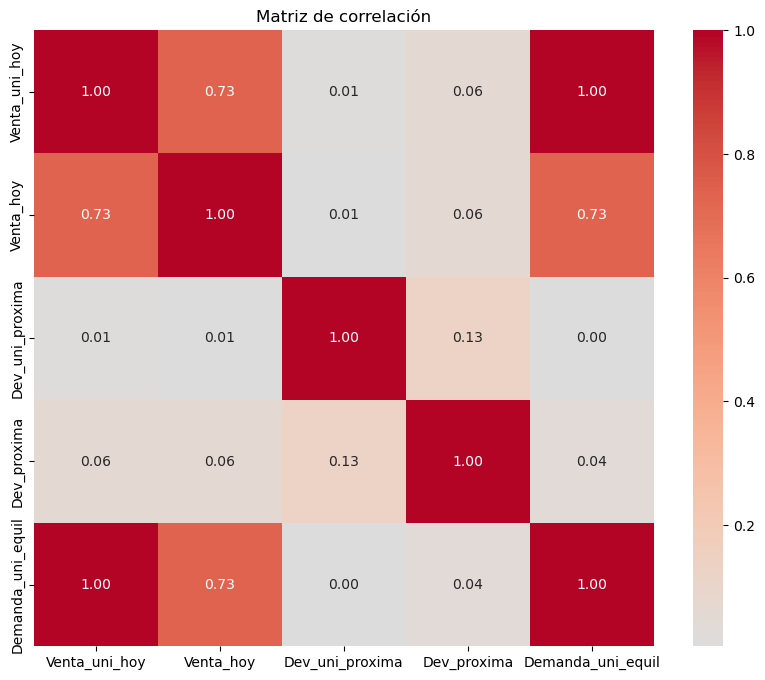

In [50]:
plt.figure(figsize=(10, 8))
sns.heatmap(df[varNumericas].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matriz de correlación")
plt.show()
#Grafica con los 70 millones de datos

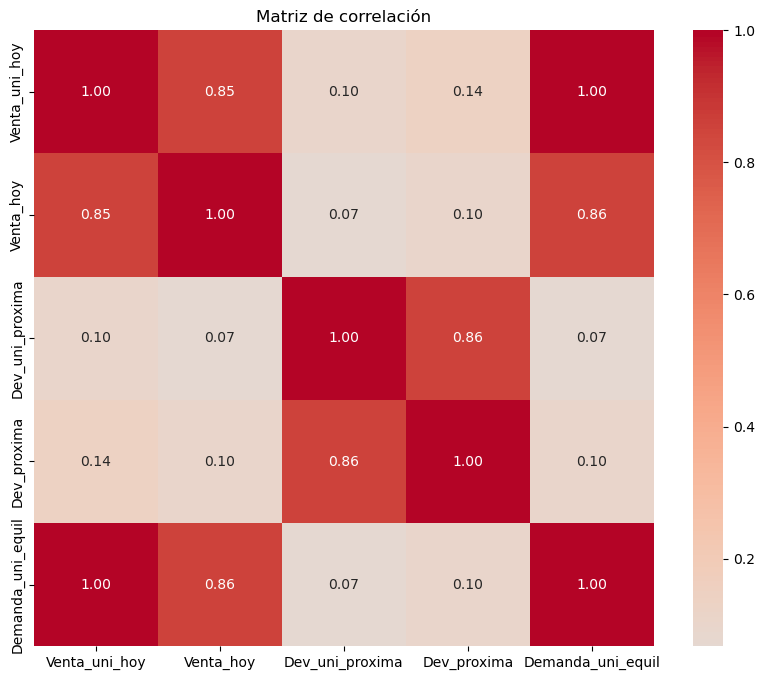

In [56]:
plt.figure(figsize=(10, 8))
sns.heatmap(df[varNumericas].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matriz de correlación")
plt.show()
#Grafica con los primeros 10 productos mas vendidos

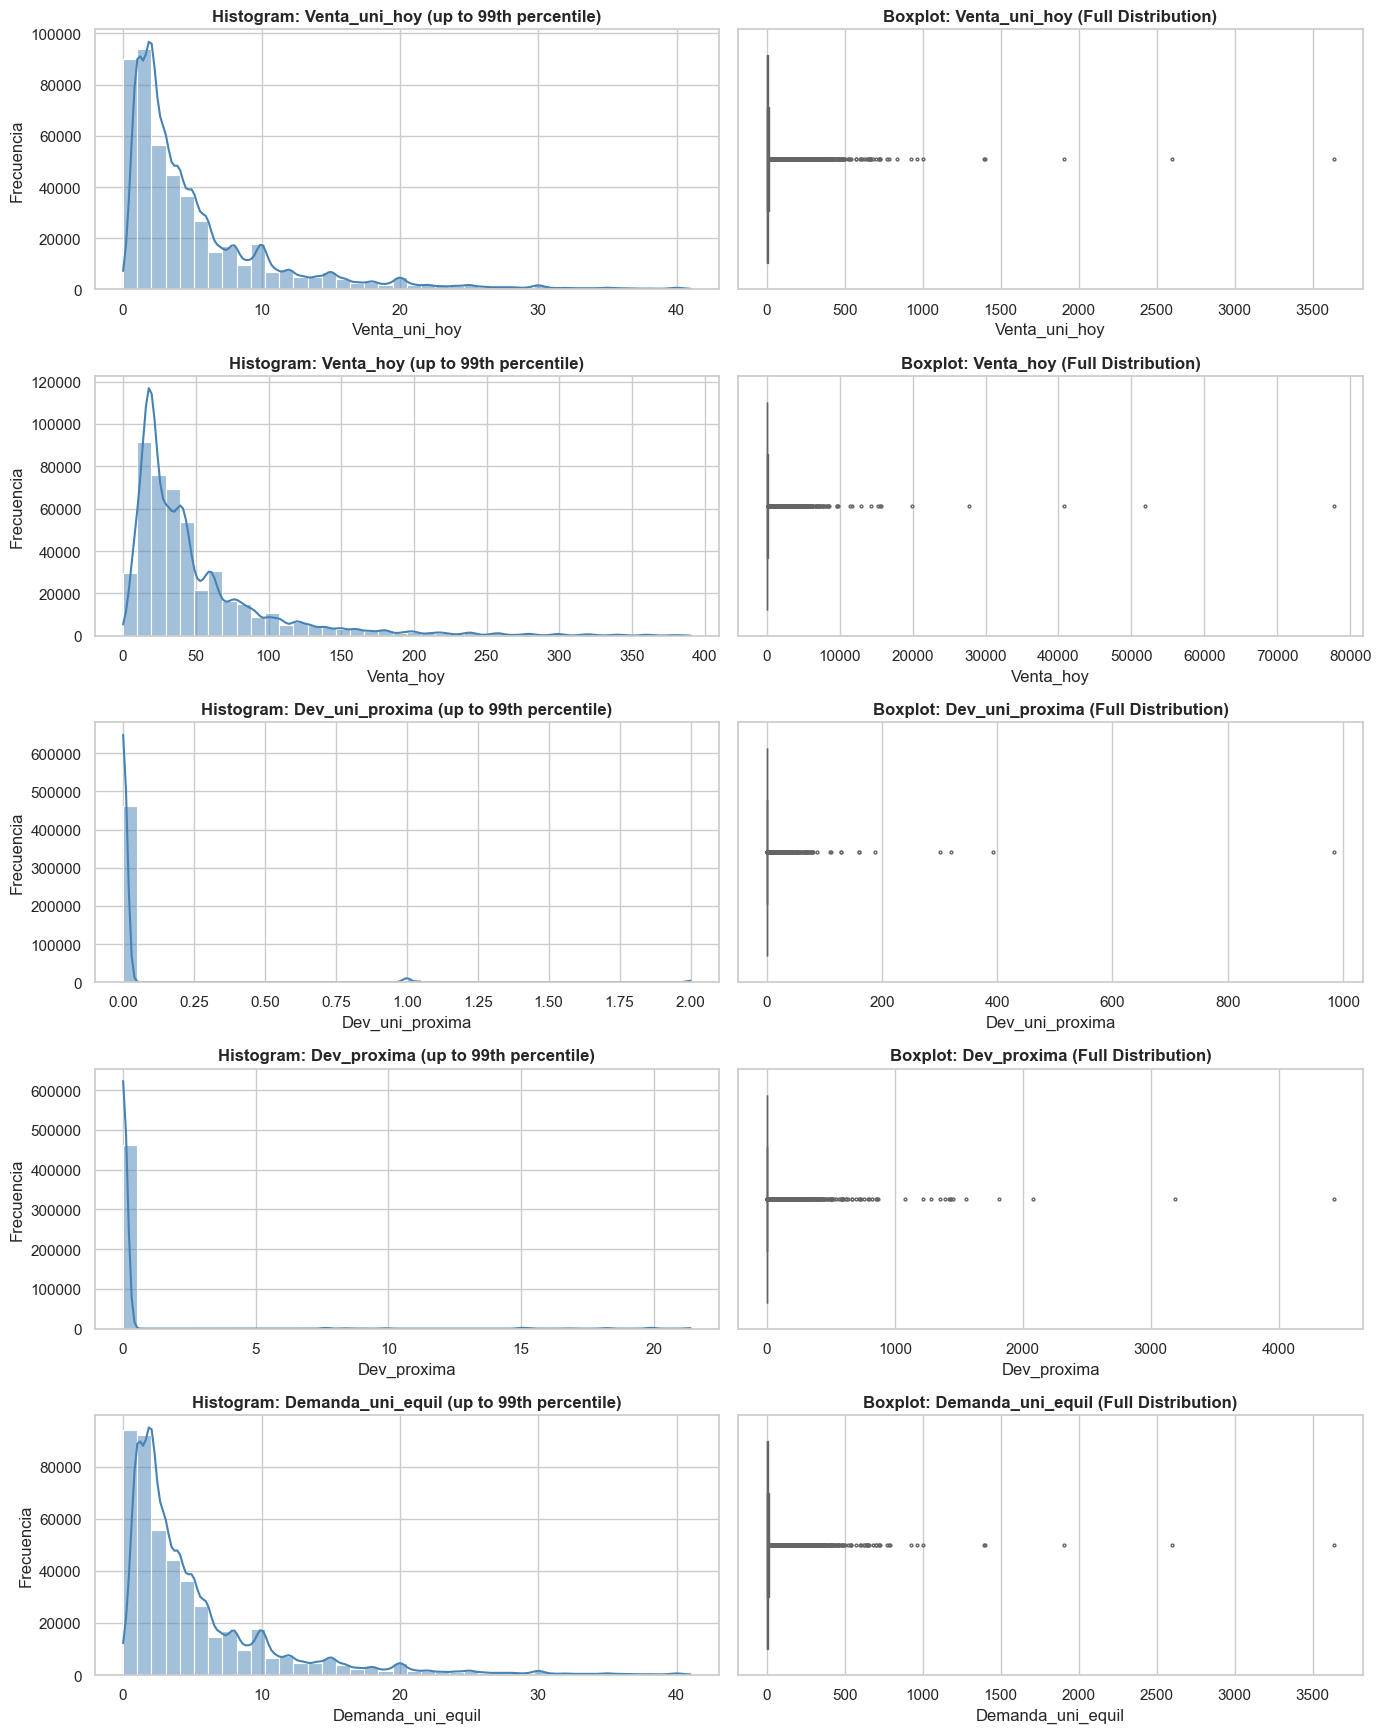

In [57]:

# Select the continuous numerical columns
numerical_cols = [
    'Venta_uni_hoy', 
    'Venta_hoy', 
    'Dev_uni_proxima', 
    'Dev_proxima', 
    'Demanda_uni_equil'
]

# Set theme style
sns.set_theme(style="whitegrid", palette="muted")

fig, axes = plt.subplots(len(numerical_cols), 2, figsize=(14, 3.5 * len(numerical_cols)))

for idx, col in enumerate(numerical_cols):
    # Clip at 99th percentile for visualization so extreme outliers don't crush the histogram
    p99 = df[col].quantile(0.99)
    subset = df[df[col] <= p99][col]
    
    # Left column: Histogram + KDE
    sns.histplot(subset, bins=40, kde=True, ax=axes[idx, 0], color='steelblue')
    axes[idx, 0].set_title(f'Histogram: {col} (up to 99th percentile)', fontweight='bold')
    axes[idx, 0].set_xlabel(col)
    axes[idx, 0].set_ylabel('Frecuencia')
    
    # Right column: Boxplot
    sns.boxplot(x=df[col], ax=axes[idx, 1], color='coral', fliersize=2)
    axes[idx, 1].set_title(f'Boxplot: {col} (Full Distribution)', fontweight='bold')
    axes[idx, 1].set_xlabel(col)

plt.tight_layout()
plt.show()